# Configuration search and final run

This notebook reads the results written by the `src/` pipeline and reports:

1. how the data is split and what a naive baseline scores,
2. a random search over model, training, data and federation settings,
3. multi-seed reruns of the best configurations,
4. the effect of individual settings (smoothing window, input features, local epochs, number of clients,
   window length, model size),
5. the final run with the chosen default configuration.

The dataset is a concatenation of separate simulation runs. Smoothing, windows and splits never cross a run
boundary; each run is split chronologically into train / validation / test, and each client holds whole runs.
Targets (throughput and delay) are raw, not smoothed. Configurations and rounds are chosen on **validation**
loss; test metrics are only reported. Losses are the mean squared error per sample on scaled targets; R² is in
original units. Runs are seeded and repeatable.

In [1]:
import os, sys, json
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

from src.config import load_config
from src.data.pipeline import load_federated_data
from src.data.preprocessing import load_dataset, assign_run_ids, drop_end_markers, drop_zero_runs

pd.set_option("display.width", 200, "display.max_columns", 30)
config = load_config("configs/default.yaml")
TARGETS = config["data"]["target_cols"]

# Chart styling: thin marks, recessive axes, text in ink colours
BLUE, ORANGE, INK, MUTED, GRID, SURFACE = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.labelcolor": MUTED, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "lines.linewidth": 2, "font.size": 10,
})

search = pd.read_csv("results/config_search.csv")
SETTINGS = [c for c in search.columns if "." in c or c == "features"]
SHORT = {c: c.split(".")[-1] for c in SETTINGS}
print(search.groupby("tag").agg(runs=("seed", "size"), configurations=("overrides", "nunique"),
                               hours=("seconds", lambda s: round(s.sum() / 3600, 2))))

               runs  configurations  hours
tag                                       
bidirectional     6               2   0.02
confirm          18               6   1.29
features          6               2   0.02
filter_len       21               7   0.08
hidden_size      18               6   0.20
local_epochs     15               5   0.06
num_clients      15               5   0.04
num_layers        9               3   0.06
random           90              90   4.02
window_len        9               3   0.03


## 1. Data split and naive baseline

The baseline repeats the last observed value of each target for all 5 future steps. A model is only useful
where it beats it.

In [2]:
data_cfg = config["data"]
raw = assign_run_ids(load_dataset(data_cfg["dataset_path"]), data_cfg["run_cols"])
no_markers = drop_end_markers(raw, data_cfg["max_position_step"])
clean = drop_zero_runs(no_markers, data_cfg["target_cols"])
print(f"{len(raw)} rows in {raw['run_id'].nunique()} runs; {len(raw) - len(no_markers)} end-of-log marker rows dropped; "
      f"{no_markers['run_id'].nunique() - clean['run_id'].nunique()} all-zero runs ({len(no_markers) - len(clean)} rows) dropped; "
      f"{len(clean)} rows in {clean['run_id'].nunique()} runs used")
print("run lengths (rows: number of runs):", clean.groupby("run_id").size().value_counts().sort_index().to_dict())

client_loaders, global_loaders, scalers = load_federated_data(config)
sizes = pd.DataFrame([{s: len(c[s].dataset) for s in ("train", "val", "test")} for c in client_loaders])
sizes.index.name = "client"
sizes["train"] //= 2 if config["data"]["noise_level"] else 1   # without the noise-augmented copies
print(sizes.T.assign(total=sizes.sum()).to_string())

def persistence(cfg, split):
    """Scaled MSE and per-target R² of 'repeat the last observed value' on a pooled split."""
    _, loaders, sc = load_federated_data(cfg)
    ds = loaders[split].dataset
    cols = cfg["data"]["feature_cols"]
    idx = [cols.index(t) for t in TARGETS]
    X = sc["feature"].inverse_transform(ds.X.numpy().reshape(-1, len(cols))).reshape(ds.X.shape)
    y_scaled = ds.y.numpy().reshape(-1, len(TARGETS))
    y = sc["target"].inverse_transform(y_scaled)
    pred = np.repeat(X[:, -1:, idx], ds.y.shape[1], axis=1).reshape(-1, len(TARGETS))
    row = {"loss": float(((sc["target"].transform(pred) - y_scaled) ** 2).mean())}
    row.update({f"r2_{t}": r2_score(y[:, j], pred[:, j]) for j, t in enumerate(TARGETS)})
    return row

baseline = {split: persistence(config, split) for split in ("val", "test")}
pd.DataFrame(baseline).T.round(4)

8941 rows in 49 runs; 16 end-of-log marker rows dropped; 2 all-zero runs (204 rows) dropped; 8721 rows in 47 runs used
run lengths (rows: number of runs): {48: 3, 102: 25, 240: 1, 321: 15, 324: 3}
client    0   1    2   3    4    5    6  total
train   106  96  128  96  118  102  105    751
val      45  36   51  36   45   51   39    303
test     45  36   51  36   45   51   39    303


,loss,r2_throughput,r2_delay
val,0.0185,0.9198,0.0402
test,0.0299,0.7951,-0.2453


**Reading the baseline**

- The pooled sets hold 751 training, 303 validation and 303 test samples.
- Repeating the last value is a strong baseline for throughput (R² 0.92 on validation, 0.80 on test) and a
  poor one for delay (R² 0.04 on validation and -0.25 on test, i.e. no better than always predicting the mean).
- The last 20 % of each run (test) is harder than the 20 % before it (validation): losses on the two sets
  are not on the same scale, so each is only compared with its own baseline.
- In scaled units throughput has about 6 times the variance of delay (0.15 vs 0.025), so the MSE loss, and
  with it every choice made on validation loss, is driven mostly by throughput.
- In about a quarter of the rows nothing is received and the dataset records a delay of 0, so for delay the
  model also has to predict when the link is down.

## 2. Random search

`python scripts/search_configs.py --random N --tag random` samples each setting independently from the
values listed in the script. Every run is a full in-process FedAvg simulation with seed 0, stopped once
the validation loss has not improved for 20 rounds (300 rounds at most). `features = settings` adds MCS, packet size and
transmit power to the five base inputs.

In [3]:
rnd = search[search["tag"] == "random"].sort_values("best_val_loss").reset_index(drop=True)
show = SETTINGS + ["best_round", "best_val_loss", "best_test_loss"] + [f"best_test_r2_{t}" for t in TARGETS] + ["seconds"]
print(f"{len(rnd)} configurations; 10 lowest validation losses:")
rnd[show].rename(columns=SHORT).head(10).round(4)

90 configurations; 10 lowest validation losses:


,features,hidden_size,num_layers,dropout,bidirectional,learning_rate,batch_size,local_epochs,window_len,filter_len,noise_level,fraction_fit,num_clients,best_round,best_val_loss,best_test_loss,best_test_r2_throughput,best_test_r2_delay,seconds
0,settings,32,2,0.3,True,0.0003,64,2,30,1,0.05,1.0,7,268,0.0143,0.0251,0.8087,0.0622,119.9
1,base,512,3,0.3,True,0.0030,32,5,15,10,0.05,1.0,7,29,0.0145,0.0251,0.8170,0.0203,846.5
2,settings,64,1,0.3,True,0.0010,64,5,30,10,0.02,0.7,7,16,0.0147,0.0245,0.8089,0.1149,51.8
3,base,128,3,0.0,True,0.0010,64,2,30,10,0.05,1.0,7,43,0.0148,0.0247,0.8088,0.0937,108.2
4,base,64,1,0.3,False,0.0010,64,1,30,1,0.00,1.0,7,249,0.0148,0.0246,0.8089,0.1065,43.6
5,base,32,1,0.3,False,0.0010,64,2,30,10,0.00,0.7,7,138,0.0148,0.0245,0.8098,0.1071,24.1
6,base,128,1,0.0,True,0.0030,32,5,30,10,0.02,0.7,7,6,0.0149,0.0252,0.8108,0.0448,18.0
7,base,256,1,0.0,False,0.0003,32,1,30,10,0.02,1.0,7,129,0.0149,0.0253,0.7952,0.1278,89.7
8,base,256,1,0.3,True,0.0003,32,5,30,10,0.00,0.7,7,38,0.0149,0.0245,0.8091,0.1107,114.0
9,base,32,1,0.0,True,0.0003,64,20,30,1,0.00,1.0,7,44,0.0150,0.0245,0.8112,0.0953,249.4


### Does validation loss predict test loss?

Configurations are ranked on validation loss, so the ranking is only meaningful if a lower validation loss
goes with a lower test loss.

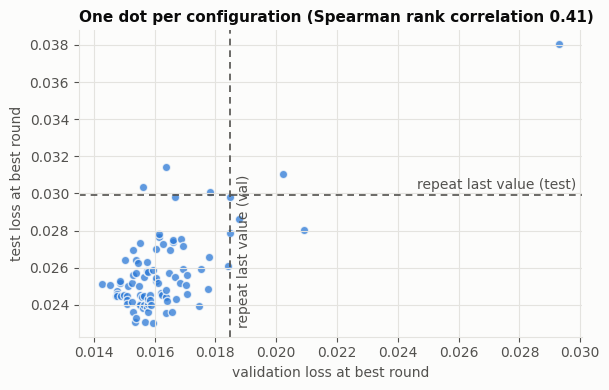

     best_val_loss  best_test_loss  best_test_r2_throughput  best_test_r2_delay
min         0.0143          0.0230                   0.6380             -0.2716
25%         0.0154          0.0243                   0.7953              0.0113
50%         0.0159          0.0251                   0.8071              0.0757
75%         0.0166          0.0264                   0.8151              0.1146
max         0.0293          0.0380                   0.8271              0.1548


In [4]:
rho = rnd["best_val_loss"].corr(rnd["best_test_loss"], method="spearman")
fig, ax = plt.subplots(figsize=(6.2, 4))
ax.scatter(rnd["best_val_loss"], rnd["best_test_loss"], s=36, color=BLUE, alpha=0.75, edgecolors=SURFACE, linewidths=1)
ax.axhline(baseline["test"]["loss"], color=MUTED, linewidth=1.2, linestyle=(0, (4, 3)))
ax.annotate("repeat last value (test)", (ax.get_xlim()[1], baseline["test"]["loss"]), textcoords="offset points",
            xytext=(-4, 5), ha="right", color=MUTED)
ax.axvline(baseline["val"]["loss"], color=MUTED, linewidth=1.2, linestyle=(0, (4, 3)))
ax.annotate("repeat last value (val)", (baseline["val"]["loss"], ax.get_ylim()[0]), textcoords="offset points",
            xytext=(5, 6), color=MUTED, rotation=90, va="bottom")
ax.set_title(f"One dot per configuration (Spearman rank correlation {rho:.2f})")
ax.set_xlabel("validation loss at best round"); ax.set_ylabel("test loss at best round")
ax.grid(True, axis="x")
plt.tight_layout(); plt.show()
print(rnd[["best_val_loss", "best_test_loss"] + [f"best_test_r2_{t}" for t in TARGETS]].describe().loc[["min", "25%", "50%", "75%", "max"]].round(4))

### Effect of each setting

Each panel shows every random-search run (dots) grouped by one setting, with the median per value (line).
The other settings vary freely, so only large, consistent gaps mean anything.

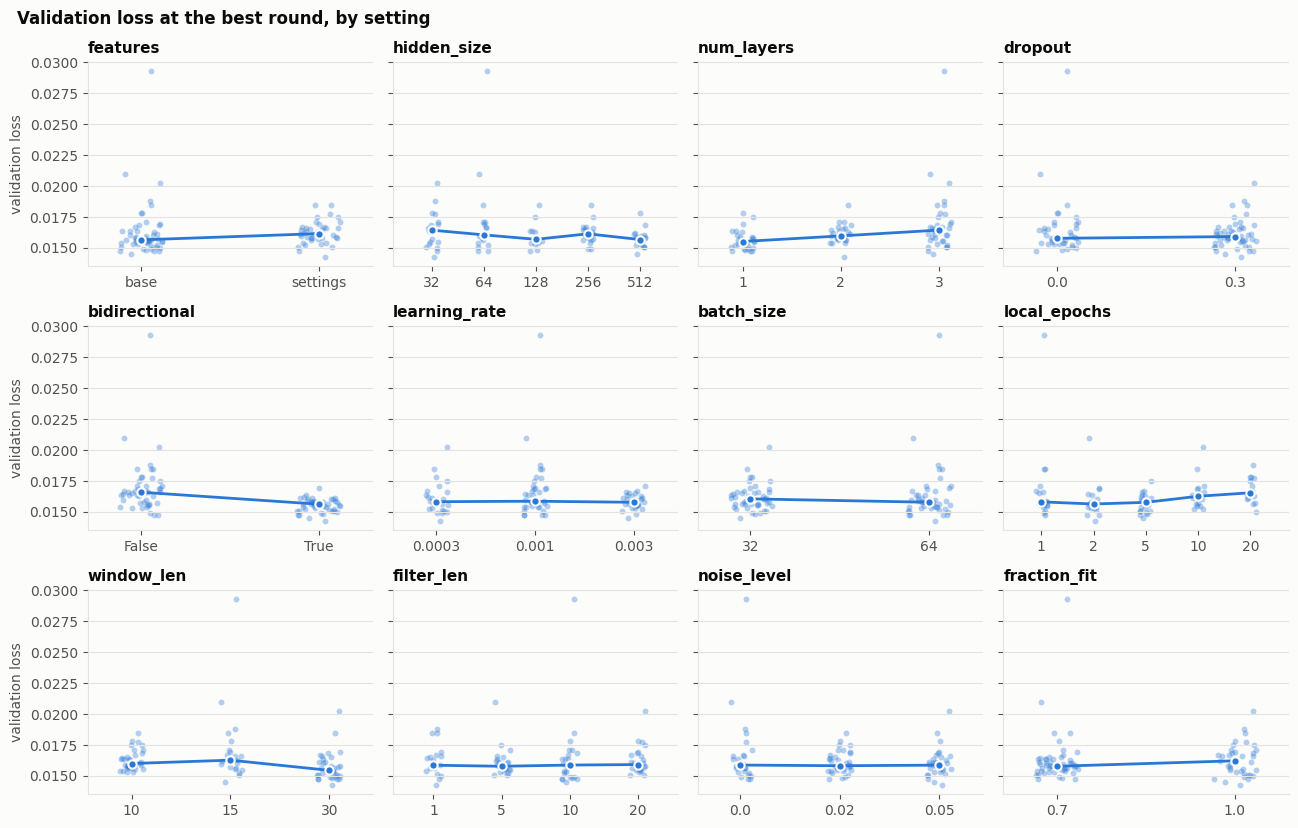

best_val_loss  best_test_loss  runs
setting       value                                        
features      base             0.0156          0.0252    51
              settings         0.0161          0.0251    39
hidden_size   32               0.0164          0.0251    18
              64               0.0160          0.0245    17
              128              0.0157          0.0245    14
              256              0.0161          0.0258    20
              512              0.0157          0.0252    21
num_layers    1                0.0155          0.0245    31
              2                0.0160          0.0248    25
              3                0.0164          0.0271    34
dropout       0.0              0.0158          0.0252    40
              0.3              0.0159          0.0251    50
bidirectional False            0.0166          0.0257    47
              True             0.0156          0.0247    43
learning_rate 0.0003           0.0158          0.0251    24
              0.001            0.0159          0.0247    39
              0.003            0.0158          0.0257    27
batch_size    32               0.0160          0.0253    45
              64               0.0158          0.0248    45
local_epochs  1                0.0158          0.0255    18
              2                0.0156          0.0250    19
              5                0.0158          0.0245    23
              10               0.0163          0.0256    16
              20               0.0165          0.0263    14
window_len    10               0.0160          0.0245    34
              15               0.0163          0.0254    21
              30               0.0154          0.0257    35
filter_len    1                0.0159          0.0246    19
              5                0.0158          0.0252    23
              10               0.0159          0.0249    24
              20               0.0159          0.0259    24
noise_level   0.0              0.0159          0.0247    24
              0.02             0.0158          0.0252    34
              0.05             0.0159          0.0254    32
fraction_fit  0.7              0.0158          0.0252    53
              1                0.0162          0.0251    37
num_clients   7                0.0159          0.0251    90

In [5]:
fig, axes = plt.subplots(3, 4, figsize=(13, 8.4), sharey=True)
for ax, setting in zip(axes.ravel(), SETTINGS):
    values = sorted(rnd[setting].unique(), key=lambda v: (isinstance(v, str), v))
    pos = {v: i for i, v in enumerate(values)}
    jitter = np.random.default_rng(0).uniform(-0.12, 0.12, len(rnd))
    ax.scatter(rnd[setting].map(pos) + jitter, rnd["best_val_loss"], s=18, color=BLUE, alpha=0.35, linewidths=0)
    medians = rnd.groupby(setting)["best_val_loss"].median()
    ax.plot(range(len(values)), [medians[v] for v in values], color=BLUE, marker="o", markersize=6,
            markeredgecolor=SURFACE, markeredgewidth=1.5)
    ax.set_xticks(range(len(values)), [str(v) for v in values])
    ax.set_title(SHORT[setting]); ax.margins(x=0.15)
for ax in axes[:, 0]:
    ax.set_ylabel("validation loss")
for ax in axes.ravel()[len(SETTINGS):]:
    ax.set_visible(False)
fig.suptitle("Validation loss at the best round, by setting", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

by_value = {SHORT[s]: rnd.groupby(rnd[s].astype(str) if rnd[s].dtype == bool else rnd[s]) for s in SETTINGS}
medians = pd.concat({name: g[["best_val_loss", "best_test_loss"]].median() for name, g in by_value.items()}).round(4)
medians.index.names = ["setting", "value"]
medians.assign(runs=pd.concat({name: g.size() for name, g in by_value.items()}))

**Reading the random search**

- 90 configurations. Hidden sizes up to 512 are sampled; 1024 takes 20 to 60 minutes per run and is tested
  in the hidden-size grid in section 4 instead.
- **Most configurations land close together.** 85 of 90 beat the baseline on validation loss and 85 on test
  loss. The middle half lies between 0.0154 and 0.0166 validation loss and between 0.0243 and 0.0264 test
  loss. The worst four are all 3-layer unidirectional models.
- Validation loss tracks test loss only loosely (rank correlation 0.41): it separates the poor
  configurations from the rest but cannot rank the dense cluster, which is why the best ones are rerun with
  new seeds below.
- Trends in the medians: fewer LSTM layers are better (0.0155 / 0.0160 / 0.0164 for 1 / 2 / 3 layers),
  bidirectional beats unidirectional (0.0156 vs 0.0166), a 30-step window beats 10 or 15 (0.0154 vs 0.0160
  and 0.0163), the five base inputs beat the eight (0.0156 vs 0.0161) and up to 5 local epochs beat 10 or
  20 (0.0156 to 0.0158 vs 0.0163 to 0.0165).
- No visible effect: smoothing window, noise level, learning rate, dropout and batch size. Hidden size
  shows no clear trend here (0.0157 to 0.0164).

## 3. Multi-seed reruns of the best configurations

`python scripts/search_configs.py --top 6 --from-tag random --seeds 1 2 3 --tag confirm` reruns the six
configurations with the lowest validation loss with three new seeds each, so these numbers do not include
the run that got each configuration selected.

In [6]:
METRICS = ["best_val_loss", "best_test_loss"] + [f"best_test_r2_{t}" for t in TARGETS]

def seed_table(df, by):
    """Mean and standard deviation over seeds, one row per value of `by`."""
    out = df.groupby(by, sort=False)[METRICS + ["best_round"]].agg(["mean", "std"]).round(4)
    out.insert(0, "runs", df.groupby(by, sort=False).size())
    return out

confirm = search[search["tag"] == "confirm"].copy()
order = confirm.groupby("overrides")["best_val_loss"].mean().sort_values().index
confirm["config"] = confirm["overrides"].map({o: f"C{i + 1}" for i, o in enumerate(order)})
confirm = confirm.sort_values(["config", "seed"])
print(confirm.drop_duplicates("config").set_index("config")[SETTINGS].rename(columns=SHORT).to_string())
seed_table(confirm, "config")

        features  hidden_size  num_layers  dropout  bidirectional  learning_rate  batch_size  local_epochs  window_len  filter_len  noise_level  fraction_fit  num_clients
config                                                                                                                                                                    
C1      settings           32           2      0.3           True         0.0003          64             2          30           1         0.05           1.0            7
C2          base           32           1      0.3          False         0.0010          64             2          30          10         0.00           0.7            7
C3          base          128           3      0.0           True         0.0010          64             2          30          10         0.05           1.0            7
C4          base           64           1      0.3          False         0.0010          64             1          30           1         0.00  

runs best_val_loss         best_test_loss         best_test_r2_throughput         best_test_r2_delay         best_round         
                     mean     std           mean     std                    mean     std               mean     std       mean      std
config                                                                                                                                 
C1        3        0.0146  0.0003         0.0252  0.0006                  0.8029  0.0025             0.0935  0.0473   240.3333  36.6379
C2        3        0.0146  0.0002         0.0248  0.0002                  0.8018  0.0055             0.1257  0.0133   104.3333  10.5040
C3        3        0.0146  0.0003         0.0245  0.0006                  0.8089  0.0064             0.1117  0.0094    41.6667   5.1316
C4        3        0.0150  0.0003         0.0256  0.0009                  0.7927  0.0116             0.1157  0.0103   192.6667  11.5036
C5        3        0.0150  0.0001         0.0253  0.0014                  0.8035  0.0146             0.0766  0.0280    22.3333   6.0277
C6        3        0.0154  0.0007         0.0272  0.0006                  0.7901  0.0078            -0.0007  0.0580    34.0000  21.5174

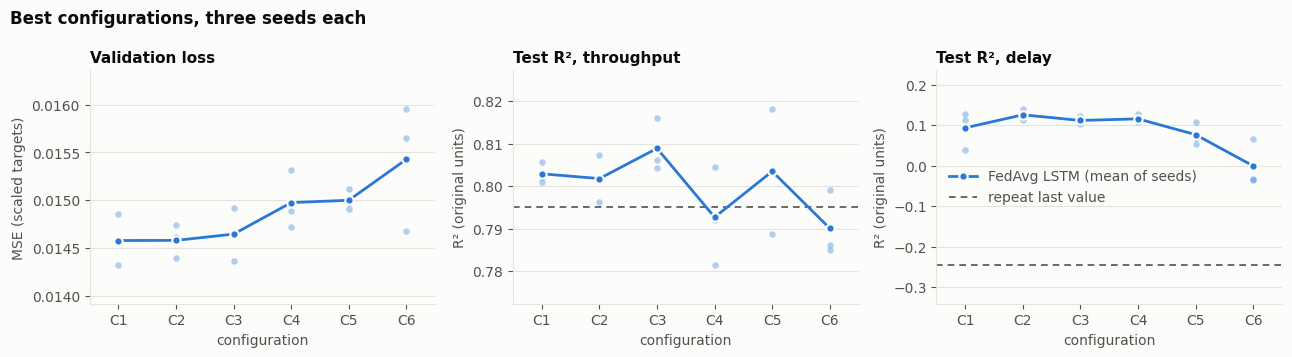

In [7]:
def seed_plot(ax, df, by, column, color=BLUE, label=None):
    """Mean across seeds as a line, individual seeds as dots, on an ordinal x axis."""
    values = list(dict.fromkeys(df[by]))
    pos = {v: i for i, v in enumerate(values)}
    ax.scatter(df[by].map(pos), df[column], s=22, color=color, alpha=0.35, linewidths=0, zorder=2)
    means = df.groupby(by, sort=False)[column].mean()
    ax.plot(range(len(values)), [means[v] for v in values], color=color, marker="o", markersize=6,
            markeredgecolor=SURFACE, markeredgewidth=1.5, label=label, zorder=3)
    ax.set_xticks(range(len(values)), [str(v) for v in values]); ax.margins(x=0.1, y=0.25)

def three_panels(df, by, xlabel, title):
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
    panels = [("best_val_loss", "Validation loss", "MSE (scaled targets)", None)]
    panels += [(f"best_test_r2_{t}", f"Test R², {t}", "R² (original units)", baseline["test"][f"r2_{t}"]) for t in TARGETS]
    for ax, (column, name, ylabel, ref) in zip(axes, panels):
        seed_plot(ax, df, by, column, label="FedAvg LSTM (mean of seeds)")
        if ref is not None:
            ax.axhline(ref, color=MUTED, linewidth=1.2, linestyle=(0, (4, 3)), label="repeat last value")
        ax.set_title(name); ax.set_ylabel(ylabel); ax.set_xlabel(xlabel)
    axes[-1].legend(frameon=False, labelcolor=MUTED, loc="best")
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold")
    plt.tight_layout(); plt.show()

three_panels(confirm, "config", "configuration", "Best configurations, three seeds each")

**Reading the reruns**

- C1, C2 and C3 are tied: mean validation loss 0.0146 for all three (C1 and C2 agree to the fifth decimal),
  with seed-to-seed standard deviations of 0.0002 to 0.0003.
- **C2 is used as the default configuration.** Among the tied three it is the simplest (one unidirectional
  layer of 32 units on the five base inputs, against two bidirectional layers on eight inputs for C1 and
  three bidirectional layers of 128 units for C3), it has the highest validation delay R² (0.32), and it
  reaches its best round after about 105 rounds where C1 needs about 240.
- C6, a 3-layer model with 512 units, was second in the search (0.0145) but averages 0.0154 with new seeds:
  its search result was a lucky seed.

## 4. One setting at a time

Each table varies a single setting of the chosen configuration and keeps everything else fixed, with three
seeds per value (`python scripts/search_configs.py --grid <setting>=... --seeds 1 2 3 --tag <tag>`).

### Smoothing window (`data.filter_len`)

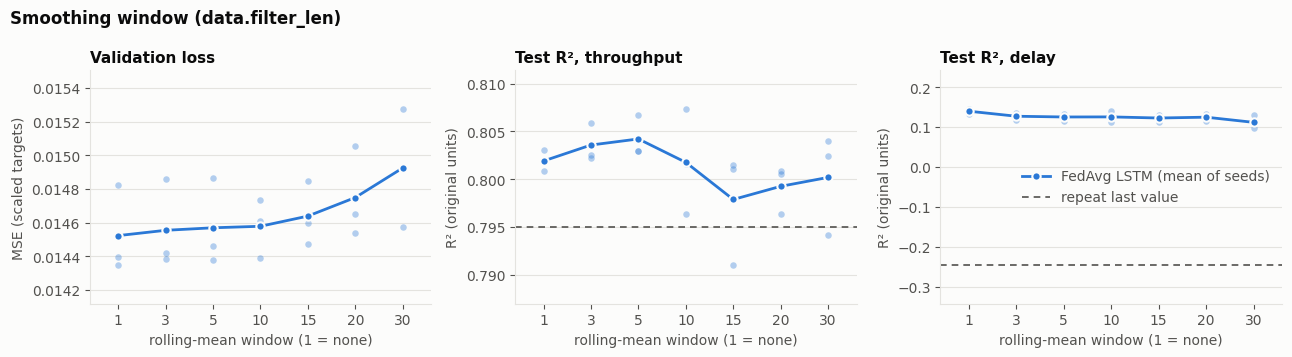

runs best_val_loss         best_test_loss         best_test_r2_throughput         best_test_r2_delay         best_round         
                              mean     std           mean     std                    mean     std               mean     std       mean      std
data.filter_len                                                                                                                                 
1                  3        0.0145  0.0003         0.0246  0.0001                  0.8019  0.0011             0.1399  0.0056   113.0000   8.1854
3                  3        0.0146  0.0003         0.0247  0.0002                  0.8036  0.0020             0.1273  0.0094   113.0000   8.1854
5                  3        0.0146  0.0003         0.0247  0.0003                  0.8042  0.0022             0.1255  0.0089   113.0000   8.1854
10                 3        0.0146  0.0002         0.0248  0.0002                  0.8018  0.0055             0.1257  0.0133   104.3333  10.5040
15                 3        0.0146  0.0002         0.0251  0.0004                  0.7979  0.0059             0.1229  0.0083   103.6667  11.5036
20                 3        0.0148  0.0003         0.0250  0.0001                  0.7993  0.0025             0.1250  0.0097   106.0000  10.8167
30                 3        0.0149  0.0003         0.0251  0.0005                  0.8002  0.0053             0.1120  0.0160   101.6667  19.6044

In [8]:
grid = search[search["tag"] == "filter_len"].sort_values(["data.filter_len", "seed"])
three_panels(grid, "data.filter_len", "rolling-mean window (1 = none)", "Smoothing window (data.filter_len)")
seed_table(grid, "data.filter_len")

**Smoothing does not help.** Validation loss is 0.0145 to 0.0146 for windows 1 (no smoothing) to 15 and
slightly worse, 0.0148 to 0.0149, for 20 and 30; the seed standard deviation is 0.0002 to 0.0003. Test loss is
flat (0.0246 to 0.0251). `filter_len` stays at 10; `filter_len: 1` is an equally good choice.

### Input features

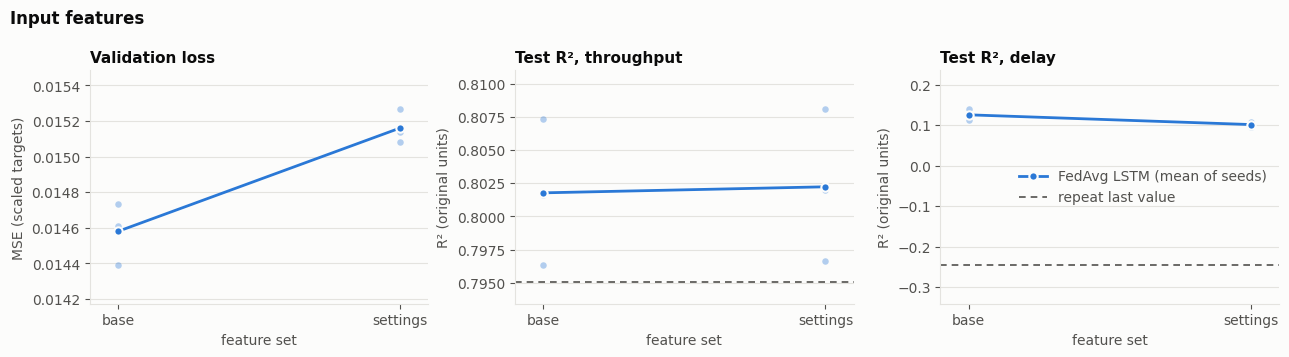

runs best_val_loss         best_test_loss         best_test_r2_throughput         best_test_r2_delay         best_round         
                       mean     std           mean     std                    mean     std               mean     std       mean      std
features                                                                                                                                 
base        3        0.0146  0.0002         0.0248  0.0002                  0.8018  0.0055             0.1257  0.0133   104.3333  10.5040
settings    3        0.0152  0.0001         0.0251  0.0004                  0.8022  0.0057             0.1016  0.0063   103.0000  32.5115

In [9]:
grid = search[search["tag"] == "features"].sort_values(["features", "seed"])
three_panels(grid, "features", "feature set", "Input features")
seed_table(grid, "features")

Adding MCS, packet size and transmit power as inputs is slightly worse on validation (0.0152 vs 0.0146) and no
better on test (0.0251 vs 0.0248). The five base features are kept.

### Local epochs per round

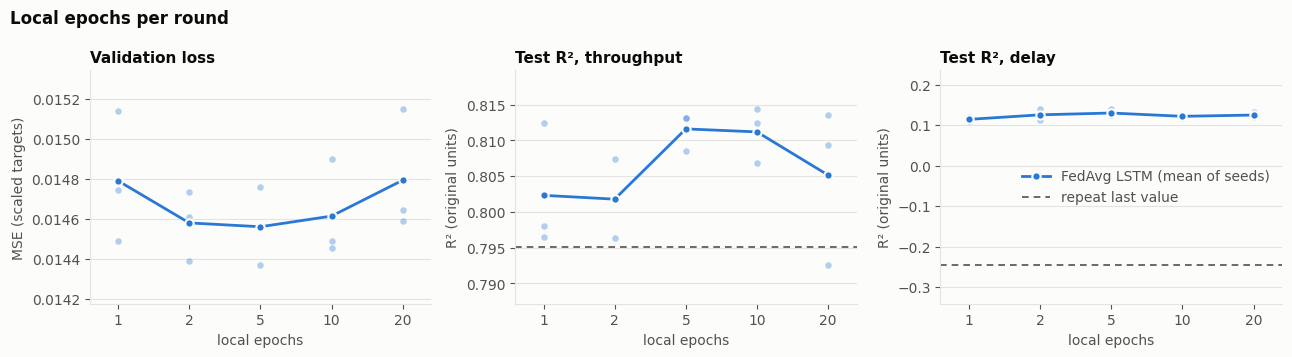

runs best_val_loss         best_test_loss         best_test_r2_throughput         best_test_r2_delay         best_round         
                                    mean     std           mean     std                    mean     std               mean     std       mean      std
training.local_epochs                                                                                                                                 
1                        3        0.0148  0.0003         0.0249  0.0006                  0.8023  0.0088             0.1144  0.0062   209.0000  53.3573
2                        3        0.0146  0.0002         0.0248  0.0002                  0.8018  0.0055             0.1257  0.0133   104.3333  10.5040
5                        3        0.0146  0.0002         0.0241  0.0001                  0.8116  0.0026             0.1301  0.0077    43.6667   4.0415
10                       3        0.0146  0.0002         0.0242  0.0002                  0.8112  0.0039             0.1220  0.0044    25.6667   4.1633
20                       3        0.0148  0.0003         0.0246  0.0008                  0.8051  0.0111             0.1251  0.0072    10.3333   2.0817

In [10]:
grid = search[search["tag"] == "local_epochs"].sort_values(["training.local_epochs", "seed"])
three_panels(grid, "training.local_epochs", "local epochs", "Local epochs per round")
seed_table(grid, "training.local_epochs")

Validation loss is 0.0146 to 0.0148 for every value, and 2, 5 and 10 local epochs are tied at 0.0146. What
changes is how many rounds are needed: 209 with one local epoch, 104 with two, 44 with five, 26 with ten and
10 with twenty. Two is kept; five would reach the same validation loss in fewer than half the rounds.

### Number of clients

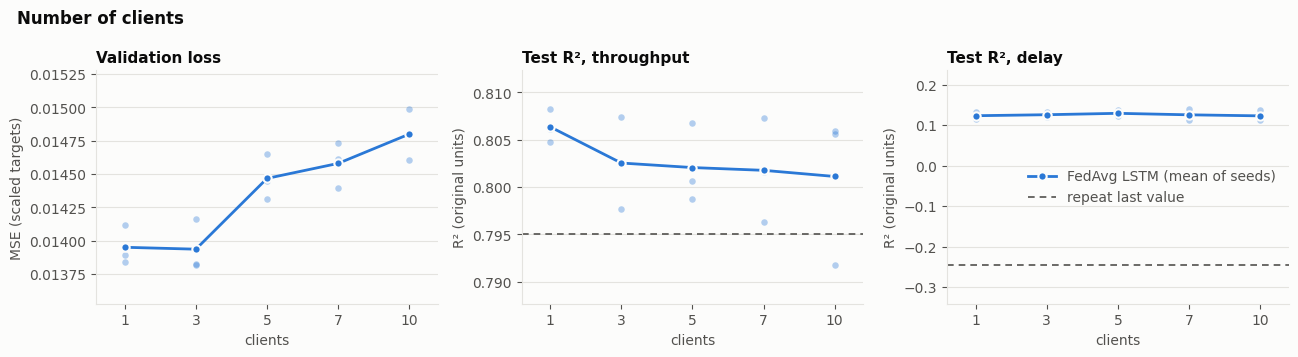

runs best_val_loss         best_test_loss         best_test_r2_throughput         best_test_r2_delay         best_round         
                                     mean     std           mean     std                    mean     std               mean     std       mean      std
federation.num_clients                                                                                                                                 
1                         3        0.0139  0.0001         0.0245  0.0001                  0.8064  0.0018             0.1234  0.0095    23.3333   6.6583
3                         3        0.0139  0.0002         0.0248  0.0003                  0.8025  0.0048             0.1259  0.0066    46.3333   5.7735
5                         3        0.0145  0.0002         0.0248  0.0003                  0.8021  0.0042             0.1294  0.0075    77.6667  15.3080
7                         3        0.0146  0.0002         0.0248  0.0002                  0.8018  0.0055             0.1257  0.0133   104.3333  10.5040
10                        3        0.0148  0.0002         0.0249  0.0004                  0.8011  0.0081             0.1231  0.0129   139.0000   7.5498

In [11]:
grid = search[search["tag"] == "num_clients"].sort_values(["federation.num_clients", "seed"])
three_panels(grid, "federation.num_clients", "clients", "Number of clients")
seed_table(grid, "federation.num_clients")

**Federation has a small cost on validation and none visible on test.** A single client holding all the data
(ordinary centralised training) reaches 0.0139 validation loss, as do 3 clients; 5, 7 and 10 clients reach
0.0145, 0.0146 and 0.0148. The gap is about 5 %, several times the seed standard deviation (0.0001 to
0.0002). Test loss is the same throughout (0.0245 to 0.0249). More clients also need more rounds: 23, 46, 78,
104 and 139. With 7 and 10 clients only 70 % of them train in each round; with 1 to 5 all of them do.

### Input window length

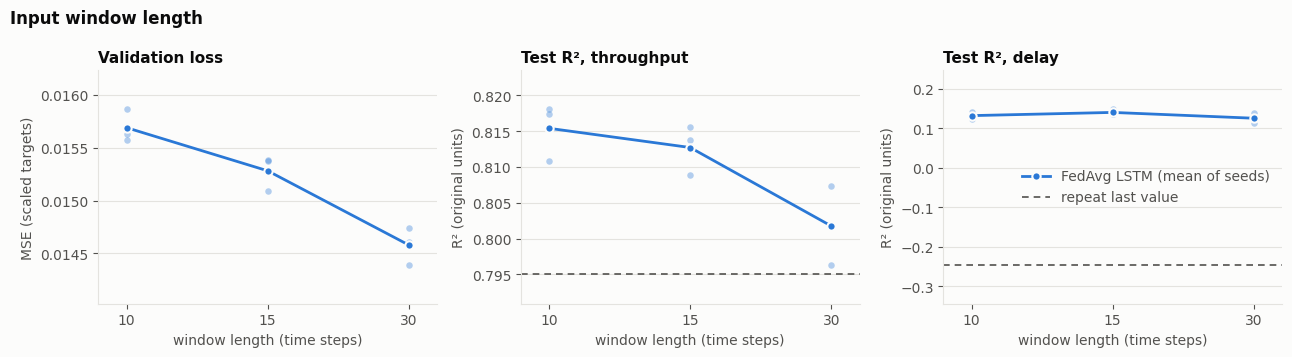

runs best_val_loss         best_test_loss         best_test_r2_throughput         best_test_r2_delay         best_round         
                              mean     std           mean     std                    mean     std               mean     std       mean      std
data.window_len                                                                                                                                 
10                 3        0.0157  0.0002         0.0238  0.0004                  0.8154  0.0040             0.1323  0.0082   100.0000  15.1327
15                 3        0.0153  0.0002         0.0239  0.0003                  0.8127  0.0035             0.1404  0.0070   108.3333   4.5092
30                 3        0.0146  0.0002         0.0248  0.0002                  0.8018  0.0055             0.1257  0.0133   104.3333  10.5040

In [12]:
grid = search[search["tag"] == "window_len"].sort_values(["data.window_len", "seed"])
three_panels(grid, "data.window_len", "window length (time steps)", "Input window length")
seed_table(grid, "data.window_len")

**Validation and test disagree here.** Validation loss falls as the input window gets longer (0.0157, 0.0153
and 0.0146 for 10, 15 and 30 steps) while test loss rises (0.0238, 0.0239 and 0.0248); both trends are well
outside the seed noise, and the validation and test samples are the same for all three lengths. The
configuration is chosen on validation, so 30 is kept, but this is the one setting where that choice does not
carry over to the test set.

### Hidden size

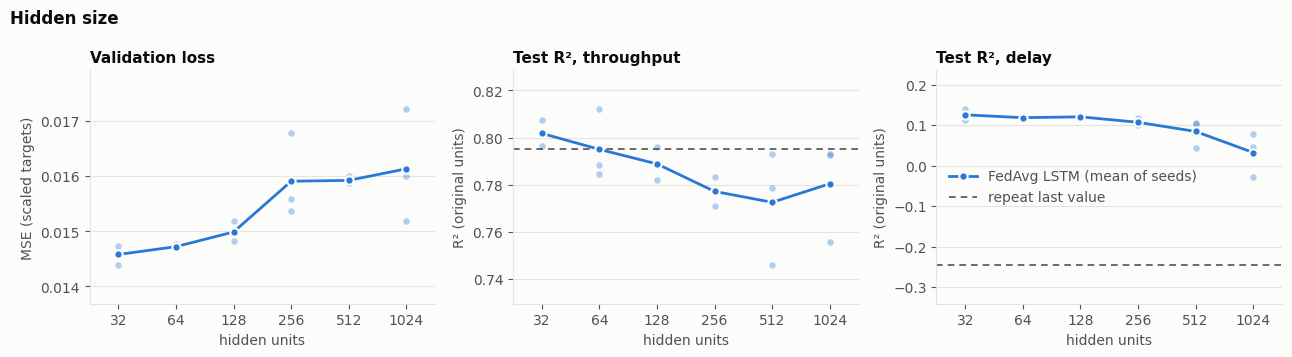

runs best_val_loss         best_test_loss         best_test_r2_throughput         best_test_r2_delay         best_round         
                                mean     std           mean     std                    mean     std               mean     std       mean      std
model.hidden_size                                                                                                                                 
32                   3        0.0146  0.0002         0.0248  0.0002                  0.8018  0.0055             0.1257  0.0133   104.3333  10.5040
64                   3        0.0147  0.0000         0.0254  0.0010                  0.7950  0.0149             0.1186  0.0035   106.3333  12.5033
128                  3        0.0150  0.0002         0.0258  0.0005                  0.7888  0.0070             0.1207  0.0028    84.0000  11.5326
256                  3        0.0159  0.0008         0.0268  0.0004                  0.7771  0.0063             0.1072  0.0087    58.6667  11.5036
512                  3        0.0159  0.0001         0.0274  0.0014                  0.7725  0.0241             0.0845  0.0360    64.6667  22.1435
1024                 3        0.0161  0.0010         0.0275  0.0011                  0.7804  0.0216             0.0324  0.0541    74.0000  17.5784

In [13]:
grid = search[search["tag"] == "hidden_size"].sort_values(["model.hidden_size", "seed"])
three_panels(grid, "model.hidden_size", "hidden units", "Hidden size")
seed_table(grid, "model.hidden_size")

Smaller is better. Validation loss rises from 0.0146 at 32 hidden units to 0.0150 at 128 and 0.0159 to 0.0161
from 256 to 1024, and test loss follows (0.0248 to 0.0275). The 1024 model also takes eight times as long.

### LSTM layers

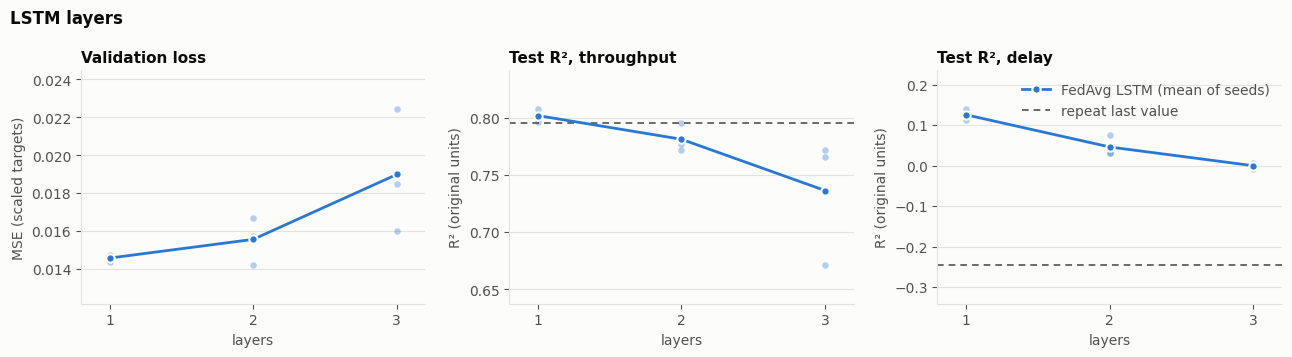

runs best_val_loss         best_test_loss         best_test_r2_throughput         best_test_r2_delay         best_round          
                               mean     std           mean     std                    mean     std               mean     std       mean       std
model.num_layers                                                                                                                                  
1                   3        0.0146  0.0002         0.0248  0.0002                  0.8018  0.0055             0.1257  0.0133   104.3333   10.5040
2                   3        0.0156  0.0013         0.0273  0.0012                  0.7811  0.0122             0.0461  0.0250   194.6667   77.7453
3                   3        0.0190  0.0032         0.0310  0.0040                  0.7363  0.0563            -0.0002  0.0067   171.0000  125.0120

In [14]:
grid = search[search["tag"] == "num_layers"].sort_values(["model.num_layers", "seed"])
three_panels(grid, "model.num_layers", "layers", "LSTM layers")
seed_table(grid, "model.num_layers")

One layer is clearly best: 0.0146 validation loss against 0.0156 for two layers and 0.0190 for three, with the
test loss following (0.0248, 0.0273, 0.0310). Two of the three 3-layer runs were still improving when they
reached the 300-round limit, so the 3-layer figure overstates the gap somewhat.

### Bidirectional LSTM

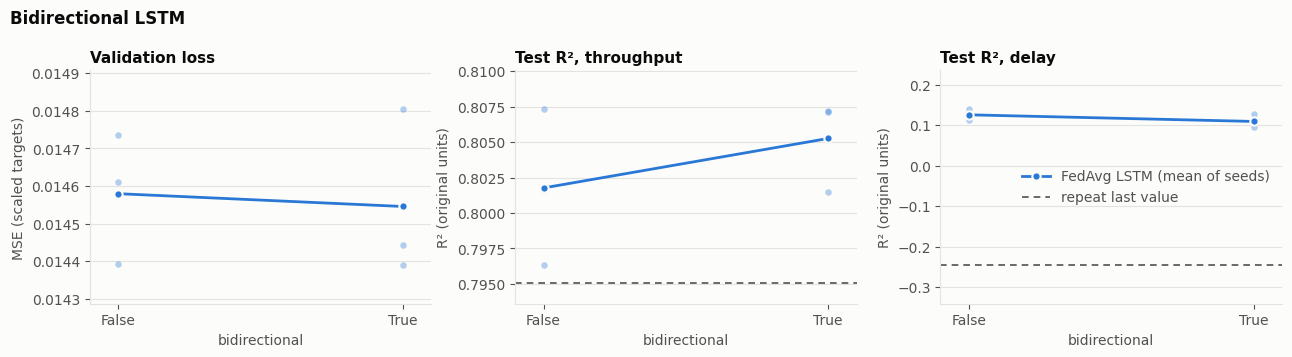

runs best_val_loss         best_test_loss         best_test_r2_throughput         best_test_r2_delay         best_round         
                                  mean     std           mean     std                    mean     std               mean     std       mean      std
model.bidirectional                                                                                                                                 
False                  3        0.0146  0.0002         0.0248  0.0002                  0.8018  0.0055             0.1257  0.0133   104.3333  10.5040
True                   3        0.0145  0.0002         0.0248  0.0003                  0.8053  0.0033             0.1093  0.0165    95.3333   7.7675

In [15]:
grid = search[search["tag"] == "bidirectional"].sort_values(["model.bidirectional", "seed"])
three_panels(grid, "model.bidirectional", "bidirectional", "Bidirectional LSTM")
seed_table(grid, "model.bidirectional")

No difference for the chosen one-layer model: 0.0146 unidirectional against 0.0145 bidirectional, with the same
test loss (0.0248). The advantage of bidirectional models in the random search comes from the deeper models.

## 5. Final run with the default configuration

`python scripts/run_simulation.py` with `configs/default.yaml`, which now holds the chosen configuration.
The server evaluates the global model on the pooled validation and test sets after every round.
`global_model_best.pt` is the round with the lowest validation loss; `global_model_final.pt` is the last
round.

In [16]:
# Snapshots of results/server_history.csv and checkpoints/training_summary.json from the final run
history = pd.read_csv("results/final_run_history.csv")
summary = json.load(open("results/final_run_summary.json"))

print({"features": config["data"]["feature_cols"], **{k: config[s][k] for s, k in [
    ("model", "hidden_size"), ("model", "num_layers"), ("model", "bidirectional"), ("model", "dropout"),
    ("training", "learning_rate"), ("training", "batch_size"), ("training", "local_epochs"),
    ("data", "window_len"), ("data", "filter_len"), ("data", "noise_level"),
    ("federation", "fraction_fit"), ("federation", "num_rounds")]}, "seed": config["seed"]})

rows = {f"best round ({summary['best']['round']})": summary["best"], f"final round ({summary['final']['round']})": summary["final"]}
final_table = pd.DataFrame(rows).T.drop(columns="round").astype(float)
final_table.loc["repeat last value"] = {f"{s}_{k}": v for s in ("val", "test") for k, v in baseline[s].items()}
final_table[["val_loss", "test_loss"] + [f"{s}_r2_{t}" for s in ("val", "test") for t in TARGETS]].round(4)

{'features': ['throughput', 'sinr', 'dlpathloss', 'delay', 'jitter'], 'hidden_size': 32, 'num_layers': 1, 'bidirectional': False, 'dropout': 0.3, 'learning_rate': 0.001, 'batch_size': 64, 'local_epochs': 2, 'window_len': 30, 'filter_len': 10, 'noise_level': 0.0, 'fraction_fit': 0.7, 'num_rounds': 200, 'seed': 42}


,val_loss,test_loss,val_r2_throughput,val_r2_delay,test_r2_throughput,test_r2_delay
best round (118),0.0143,0.0247,0.9253,0.3328,0.8037,0.1295
final round (200),0.0146,0.0247,0.9271,0.3005,0.8058,0.1161
repeat last value,0.0185,0.0299,0.9198,0.0402,0.7951,-0.2453


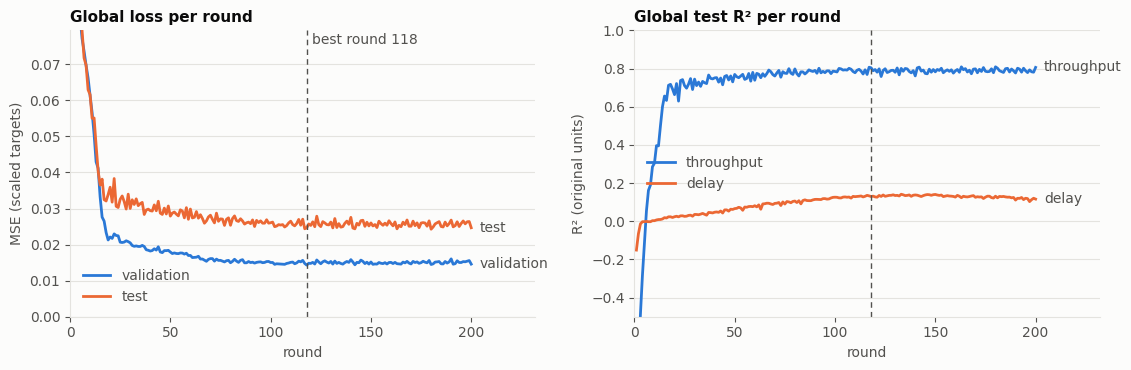

In [17]:
trained = history[history["round"] > 0]
best_round = summary["best"]["round"]

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
ax = axes[0]
for column, color, name in [("val_loss", BLUE, "validation"), ("test_loss", ORANGE, "test")]:
    ax.plot(trained["round"], trained[column], color=color, label=name)
    ax.annotate(name, (trained["round"].iloc[-1], trained[column].iloc[-1]), textcoords="offset points",
                xytext=(6, 0), va="center", color=MUTED)
ax.set_ylim(0, min(trained[["val_loss", "test_loss"]].max().max(), 3 * trained["test_loss"].median()))
ax.axvline(best_round, color=MUTED, linewidth=1, linestyle=(0, (4, 3)))
ax.annotate(f"best round {best_round}", (best_round, ax.get_ylim()[1]), textcoords="offset points", xytext=(4, -10), color=MUTED)
ax.set_title("Global loss per round"); ax.set_xlabel("round"); ax.set_ylabel("MSE (scaled targets)")
ax.legend(frameon=False, labelcolor=MUTED, loc="lower left")

ax = axes[1]
for target, color in zip(TARGETS, [BLUE, ORANGE]):
    ax.plot(trained["round"], trained[f"test_r2_{target}"], color=color, label=target)
    ax.annotate(target, (trained["round"].iloc[-1], trained[f"test_r2_{target}"].iloc[-1]),
                textcoords="offset points", xytext=(6, 0), va="center", color=MUTED)
ax.axvline(best_round, color=MUTED, linewidth=1, linestyle=(0, (4, 3)))
ax.set_title("Global test R² per round"); ax.set_xlabel("round"); ax.set_ylabel("R² (original units)")
ax.set_ylim(max(-0.5, trained[[f"test_r2_{t}" for t in TARGETS]].min().min() - 0.05), 1)
ax.legend(frameon=False, labelcolor=MUTED, loc="center left")
for ax in axes:
    ax.set_xlim(0, trained["round"].iloc[-1] * 1.16)
plt.tight_layout(); plt.show()

**Reading the final run**

- One run with seed 42, 200 rounds, about 30 seconds on an RTX 3050. Repeating it gives the same numbers.
- The best round is 118 (validation loss 0.0143). After it the validation loss moves between 0.0143 and
  0.0160 without improving; the final round is at 0.0146.
- Against repeating the last value on the test set: loss 0.0247 vs 0.0299 (17 % lower), throughput R²
  0.804 vs 0.795, delay R² 0.129 vs -0.245.
- The same configuration with seeds 1 to 3 (section 3, C2) averages 0.0146 validation loss, 0.0248 test
  loss, 0.802 throughput R² and 0.126 delay R², so this run is typical.

## Conclusions

1. **Chosen default**: unidirectional LSTM, 1 layer, 32 hidden units, learning rate 0.001, batch size 64,
   2 local epochs, 5 of 7 clients per round, 200 rounds, no noise augmentation, 30-step window,
   `filter_len` 10, five base features.
2. **Small and shallow wins.** Across 207 runs the clear effects are model depth and size: one layer beats
   two and three, and 32 hidden units beat anything larger. Most other settings change the validation loss
   by no more than the seed-to-seed noise.
3. **Smoothing the inputs does not help**, and the extra radio-setting inputs make things slightly worse.
4. **FedAvg costs about 5 % in validation loss** against centralised training on the same data, and nothing
   visible on the test set; it needs four to five times as many rounds with seven clients.
5. **What the model actually achieves** on the test set: a loss 17 % below repeating the last value,
   throughput R² slightly above that baseline (0.804 vs 0.795) and delay R² of 0.13 against -0.25. A delay R² of
   0.13 is still only a little better than always predicting the mean delay.
6. **Limits**: validation and test are later parts of the same simulation runs used for training, so these
   numbers measure forecasting under radio settings the model has already seen. The loss is dominated by
   throughput, so nothing here was tuned for delay. Validation and test disagree on the window length.
   More than a third of the samples (107 of the 303 test samples) come from stretches where throughput and
   delay do not change at all; the model and the baseline both get these right.